In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RESULTS_FOLDER = Path("../../results/KNN_group_results")
RESULTS_FOLDER.mkdir(parents=True, exist_ok=True)

ACTIVITIES = ["walking", "walking_upstairs", "walking_downstairs"]
LABEL_COLUMNS = ["split", "activity", "participant", "position", "platform", "recording_id"]

# Load the features made by build_features.py
data = pd.read_csv("../../data/processed/group/group_features.csv")
X = data.drop(columns=LABEL_COLUMNS)    # the 84 features
y = data["activity"]                    # the answers

print(f"{len(data):,} windows x {X.shape[1]} features")
print(data.groupby(["participant", "activity"]).size().unstack(fill_value=0))

25,232 windows x 84 features
activity     walking  walking_downstairs  walking_upstairs
participant                                               
P01             9792                 713               847
P02             6399                 619               741
P03             4614                 620               887


In [5]:
def undersample_walking(X_train, y_train):
    # k-NN would produce inaccruate results due to the massive class imbalance, so balancing the training data,
    # randomly keep only as many walking windows as the largest stair class [walking_upstairs].
    is_walking = y_train == "walking"
    number_to_keep = y_train[~is_walking].value_counts().max()
    kept_walking = y_train[is_walking].sample(n=number_to_keep, random_state=42).index
    keep = y_train.index.isin(kept_walking) | ~is_walking
    return X_train[keep], y_train[keep]


def run_knn(is_test, name, file_name, k=5):
    # Balance, scale, train, test, print the results and return the macro F1.
    X_train, X_test = X[~is_test], X[is_test]
    y_train, y_test = y[~is_test], y[is_test]

    # Balance the training data only (the test data isnt touched)
    X_train, y_train = undersample_walking(X_train, y_train)

    # Learn the scaling from the training data only, then apply it to both
    scaler = MinMaxScaler(feature_range=(-1, 1))
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Train and predict
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    predictions = knn.predict(X_test_scaled)

    # Results
    macro_f1 = f1_score(y_test, predictions, average="macro")
    print(f"===== k-NN (k={k}): {name} =====")
    print(f"Train: {len(y_train):,} windows (after undersampling walking)   Test: {len(y_test):,} windows")
    print(f"Accuracy: {accuracy_score(y_test, predictions):.3f}")
    print(f"Macro F1: {macro_f1:.3f}\n")
    print(classification_report(y_test, predictions, labels=ACTIVITIES, digits=3, zero_division=0))

    # Confusion matrix
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=ACTIVITIES, normalize="true",
                                            cmap="Blues", xticks_rotation=30)
    plt.title(f"k-NN: {name}")
    plt.tight_layout()
    plt.savefig(RESULTS_FOLDER / f"KNN_group_{file_name}_confusion_matrix.png", dpi=150)
    plt.show()

    # Scores per activity
    report = pd.DataFrame(classification_report(y_test, predictions, labels=ACTIVITIES,
                                                output_dict=True, zero_division=0)).T
    per_activity = report.loc[ACTIVITIES, ["precision", "recall", "f1-score"]]
    per_activity.plot(kind="bar", figsize=(7, 4), ylim=(0, 1), rot=0)
    plt.title(f"k-NN: scores per activity ({name})")
    plt.ylabel("Score")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(RESULTS_FOLDER / f"KNN_group_{file_name}_per_activity.png", dpi=150)
    plt.show()

    return macro_f1

===== k-NN (k=5): 70/30 by recording =====
Train: 5,110 windows (after undersampling walking)   Test: 8,101 windows
Accuracy: 0.945
Macro F1: 0.861

                    precision    recall  f1-score   support

           walking      0.989     0.954     0.971      6935
  walking_upstairs      0.782     0.890     0.833       626
walking_downstairs      0.690     0.893     0.778       540

          accuracy                          0.945      8101
         macro avg      0.820     0.912     0.861      8101
      weighted avg      0.953     0.945     0.948      8101



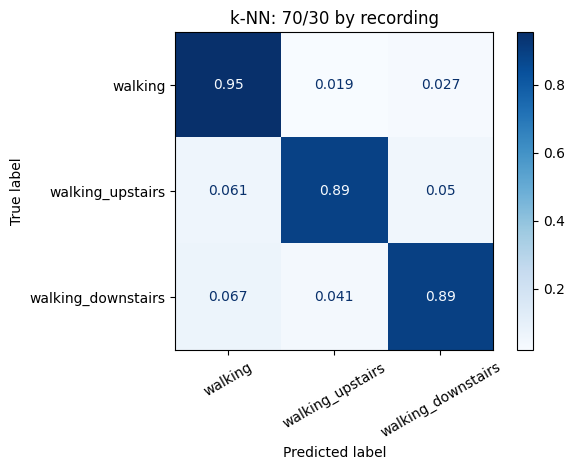

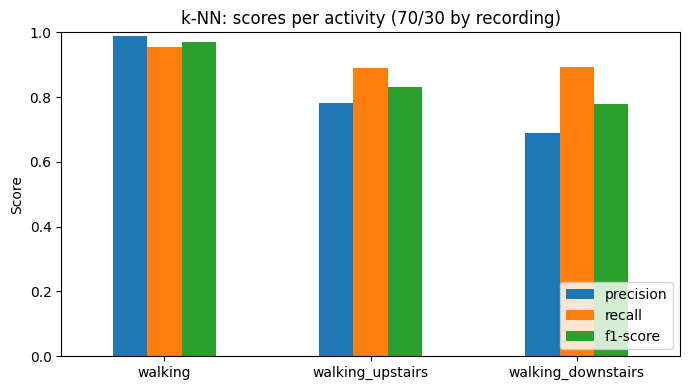

In [6]:
# 70/30 split by recording (read from the split column)
results = {}

is_test = data["split"] == "test"
results["70/30 by recording"] = run_knn(is_test, "70/30 by recording", "70_30")

===== k-NN (k=5): train on others, test on P01 (pocket) =====
Train: 4,495 windows (after undersampling walking)   Test: 11,352 windows
Accuracy: 0.772
Macro F1: 0.476

                    precision    recall  f1-score   support

           walking      0.901     0.853     0.876      9792
  walking_upstairs      0.641     0.351     0.453       847
walking_downstairs      0.070     0.160     0.098       713

          accuracy                          0.772     11352
         macro avg      0.538     0.454     0.476     11352
      weighted avg      0.829     0.772     0.796     11352



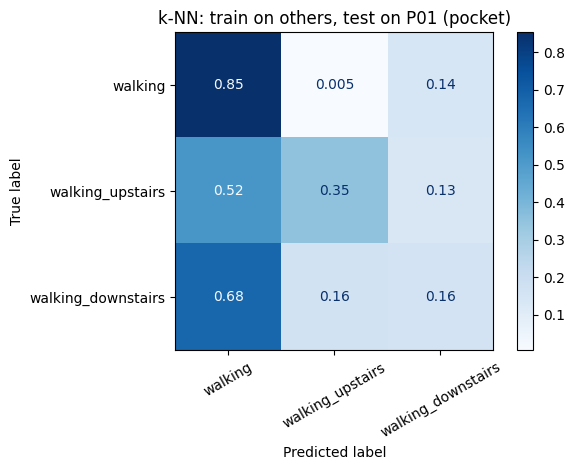

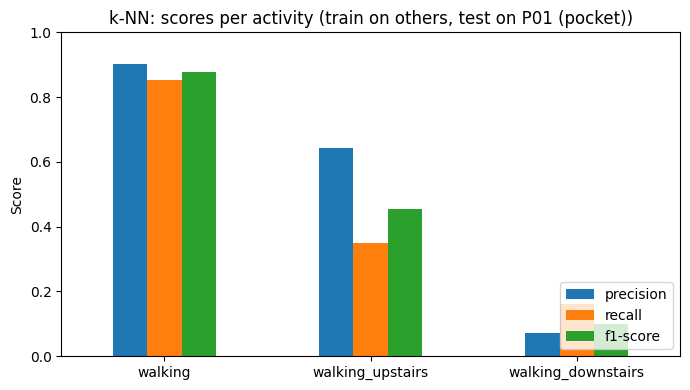

===== k-NN (k=5): train on others, test on P02 (waist) =====
Train: 4,801 windows (after undersampling walking)   Test: 7,759 windows
Accuracy: 0.528
Macro F1: 0.280

                    precision    recall  f1-score   support

           walking      0.780     0.616     0.688      6399
  walking_upstairs      0.097     0.177     0.125       741
walking_downstairs      0.021     0.045     0.028       619

          accuracy                          0.528      7759
         macro avg      0.299     0.279     0.280      7759
      weighted avg      0.654     0.528     0.582      7759



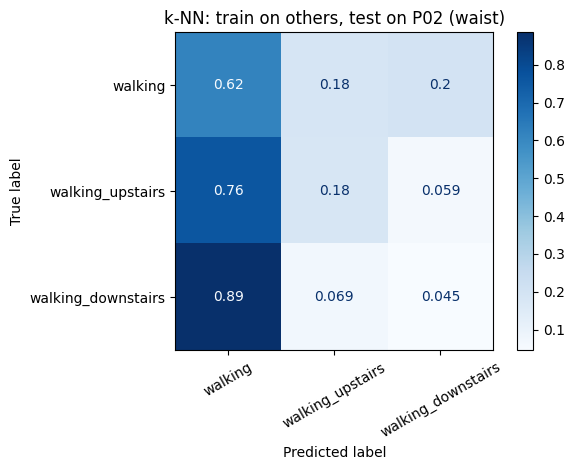

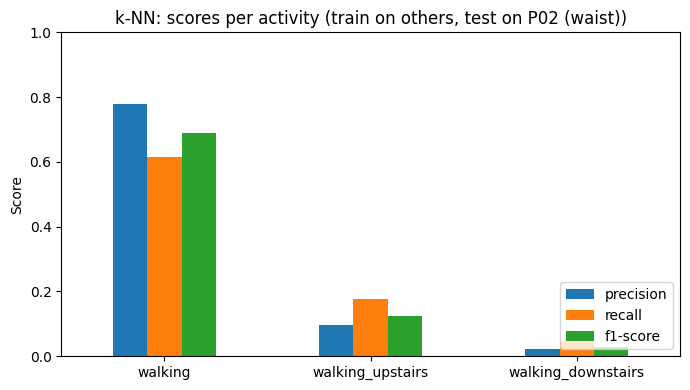

===== k-NN (k=5): train on others, test on P03 (hand) =====
Train: 4,508 windows (after undersampling walking)   Test: 6,121 windows
Accuracy: 0.654
Macro F1: 0.387

                    precision    recall  f1-score   support

           walking      0.793     0.776     0.784      4614
  walking_upstairs      0.268     0.463     0.339       887
walking_downstairs      0.178     0.021     0.038       620

          accuracy                          0.654      6121
         macro avg      0.413     0.420     0.387      6121
      weighted avg      0.655     0.654     0.644      6121



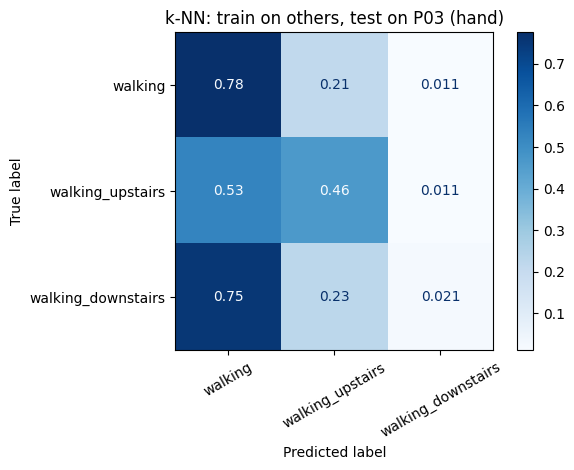

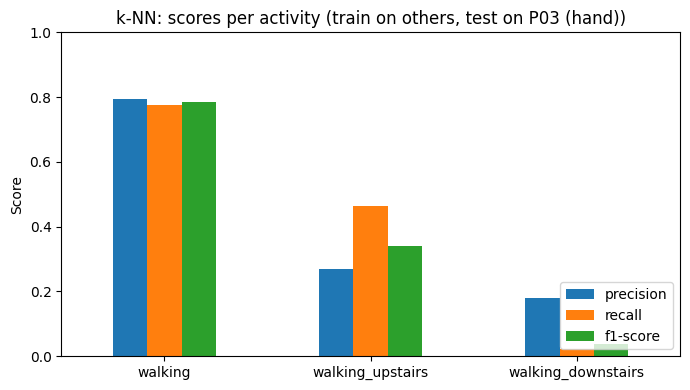

In [7]:
# Train on two people, test on the third (3 runs, alternating test person)
for person in sorted(data["participant"].unique()):
    is_test = data["participant"] == person
    position = data.loc[is_test, "position"].iloc[0]
    name = f"train on others, test on {person} ({position})"
    results[f"Test on {person} ({position})"] = run_knn(is_test, name, f"test_{person}")

In [8]:
# Summary of the 4 runs results
held_out_scores = [score for split, score in results.items() if split.startswith("Test on")]
results["Leave-one-participant-out average"] = sum(held_out_scores) / len(held_out_scores)

summary = pd.Series(results, name="Macro F1").round(3).to_frame()
summary.to_csv(RESULTS_FOLDER / "KNN_group_summary.csv")
summary

,Macro F1
70/30 by recording,0.861
Test on P01 (pocket),0.476
Test on P02 (waist),0.280
Test on P03 (hand),0.387
Leave-one-participant-out average,0.381
